# 3.0 How does one trust compare with its peers?

A finance director preparing for a board meeting wants to know **where their trust sits within its own
sector**. This notebook benchmarks one trust against the other trusts in its sector on five measures, and
tracks it against the sector median over time.

The trust is a parameter. Set the `TRUST_ORG_CODE` environment variable to any ODS code before launching
Jupyter. If it is not set, the notebook picks the trust with the lowest operating margin in the latest
year, so it always has a meaningful example to show.

**Data:** NHS England Trust Accounts Consolidation (TAC), read from `analysis/data/` (exported from the
`nhs_gold` views by `python/reporting/export_for_analysis.py`). Annual, actuals only, £000s in the data and
£m on the charts. Operating surplus is the TAC SoCI line `SCI0140A` as each trust reported it. It is not
NHS England's adjusted financial performance measure, which excludes impairments and some transfers.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make analysis/nhs_analysis.py importable whether this runs from the repo root or this folder
ANALYSIS_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "nhs_analysis.py").exists()
                    or (p / "analysis" / "nhs_analysis.py").exists())
ANALYSIS_DIR = ANALYSIS_DIR if (ANALYSIS_DIR / "nhs_analysis.py").exists() else ANALYSIS_DIR / "analysis"
sys.path.insert(0, str(ANALYSIS_DIR))

import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format
import os

In [2]:
ty = nhs.load_trust_year()
years = nhs.financial_years(ty)
latest_year = years[-1]
latest = ty[ty.financial_year == latest_year]

ORG_CODE = os.environ.get("TRUST_ORG_CODE") or latest.nsmallest(1, "operating_margin_pct").org_code.iloc[0]
trust = ty[ty.org_code == ORG_CODE]
if trust.empty:
    raise ValueError(f"No trust with ODS code {ORG_CODE!r} in the data")
name = trust.organisation_name.iloc[-1]
sector = trust.sector.iloc[-1]
peers = latest[latest.sector == sector]
print(f"{name} ({ORG_CODE}), {sector} sector: compared with {len(peers) - 1} peers in {latest_year}")

West Suffolk NHS Foundation Trust (RGR), Acute sector: compared with 117 peers in 2023/24


## 3.1 Position within the sector

Each grey dot is one peer trust in the same sector; the coloured dot is the selected trust. Each panel has
its own scale. For operating margin, EBITDA margin, current ratio and cash days, further right is
stronger; for pay as a share of income, further left is lower cost.

If the trust's operating margin is far below its EBITDA margin, the gap is depreciation, amortisation and
impairments. A large gap in a single year usually means an impairment (a non-cash write-down of
buildings or equipment), so check the trust's impairments line before treating it as an operating
problem.

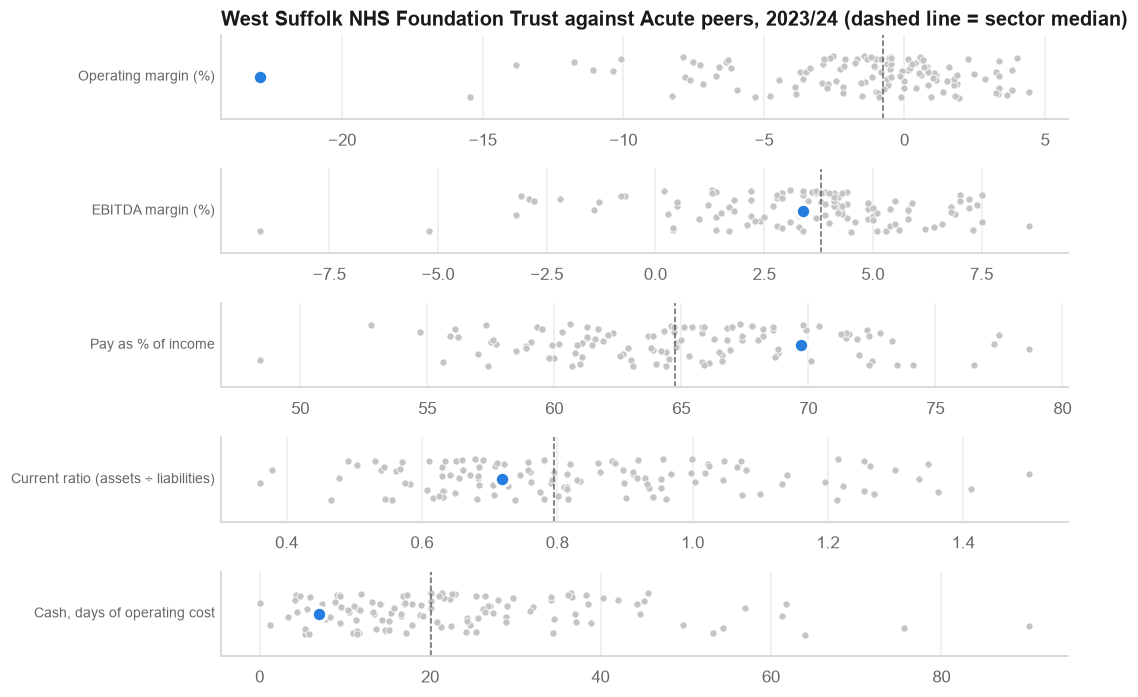

In [3]:
MEASURES = {
    "operating_margin_pct": "Operating margin (%)",
    "ebitda_margin_pct": "EBITDA margin (%)",
    "pay_pct_income": "Pay as % of income",
    "current_ratio": "Current ratio (assets ÷ liabilities)",
    "cash_days": "Cash, days of operating cost",
}
colour = nhs.SECTOR_COLOURS[sector]
this = peers[peers.org_code == ORG_CODE]

fig, axes = plt.subplots(len(MEASURES), 1, figsize=(10, 6.5))
for ax, (col, label) in zip(axes, MEASURES.items()):
    others = peers[peers.org_code != ORG_CODE]
    ax.scatter(others[col], np.random.default_rng(0).uniform(-0.25, 0.25, len(others)),
               s=22, color=nhs.CONTEXT_GREY, edgecolor="white", linewidth=0.5)
    ax.axvline(peers[col].median(), color=nhs.TEXT_SECONDARY, linewidth=1, linestyle="--")
    ax.scatter(this[col], [0], s=90, color=colour, edgecolor="white", linewidth=2, zorder=3)
    ax.set_yticks([]); ax.set_ylim(-0.5, 0.5)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=9)
    ax.grid(axis="y", visible=False)
axes[0].set_title(f"{name} against {sector} peers, {latest_year} (dashed line = sector median)")
fig.tight_layout()
plt.show()

## 3.2 Rank within the sector

The percentile shows where the trust sits among its sector peers (100 = highest value in the sector).
For pay as a share of income, a lower percentile means lower cost.

In [4]:
ranks = peers.set_index("org_code")[list(MEASURES)].rank(pct=True) * 100
summary = pd.DataFrame({
    "Trust": this.set_index("org_code").loc[ORG_CODE, list(MEASURES)],
    "Sector median": peers[list(MEASURES)].median(),
    "Percentile in sector": ranks.loc[ORG_CODE],
}).rename(index=MEASURES)
summary

,Trust,Sector median,Percentile in sector
Operating margin (%),-22.9,-0.8,0.8
EBITDA margin (%),3.4,3.8,42.8
Pay as % of income,69.7,64.8,79.7
Current ratio (assets ÷ liabilities),0.7,0.8,38.5
"Cash, days of operating cost",7.0,20.1,11.0


## 3.3 Trend against the sector median

The selected trust over every year in the data, against the median trust in its sector.

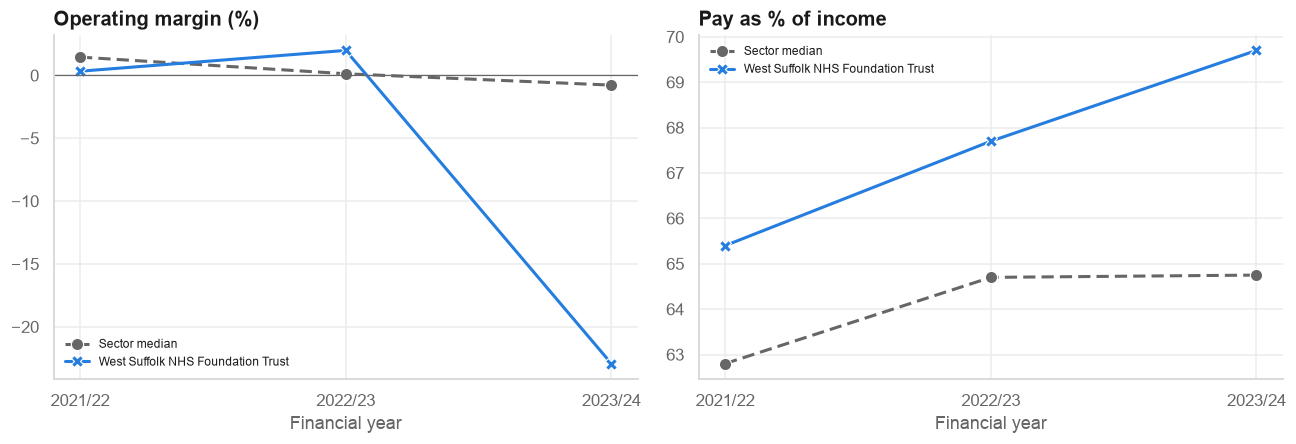

In [5]:
trend = (ty[ty.sector == sector]
         .groupby("financial_year")[["operating_margin_pct", "pay_pct_income"]].median()
         .assign(series="Sector median"))
trend = pd.concat([trend.reset_index(),
                   trust[["financial_year", "operating_margin_pct", "pay_pct_income"]].assign(series=name)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (col, label) in zip(axes, [("operating_margin_pct", "Operating margin (%)"),
                                   ("pay_pct_income", "Pay as % of income")]):
    sns.lineplot(data=trend, x="financial_year", y=col, hue="series", style="series",
                 palette={name: colour, "Sector median": nhs.TEXT_SECONDARY},
                 markers=True, markersize=8, linewidth=2, dashes={name: "", "Sector median": (4, 2)},
                 ax=ax)
    ax.set(title=label, xlabel="Financial year", ylabel=None)
    ax.legend(title=None, fontsize=8)
axes[0].axhline(0, color=nhs.TEXT_SECONDARY, linewidth=0.8)
fig.tight_layout()
plt.show()